# **TP — Modèles génératifs avec PyTorch sur MNIST**

**Première partie** : modèle discriminatif, auto-encodeur simple et VAE.

Plan :
0. Environnement (projet UV, dépendances, device)
1. Chargement du dataset MNIST
2. Modèle discriminatif : apprendre $P(y|x)$
3. Auto-encodeur simple : apprendre $x \rightarrow z \rightarrow \hat x$
4. Variational Auto-Encoder (VAE) : apprendre une distribution latente et générer de nouvelles images

## 0. Préparation de l'environnement

Projet créé avec UV :

```bash
uv init --python=3.11
uv venv
.venv\Scripts\activate
uv add ipykernel torch torchvision torcheval matplotlib numpy
```

Kernel du notebook : l'interpréteur `.venv` du projet (Python 3.11).

In [1]:
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

print("Python      :", sys.version.split()[0])
print("Interpréteur:", sys.executable)
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device      :", device)

Python      : 3.11.14
Interpréteur: C:\Users\Salah\Desktop\lab_pytorchV2 tp2\.venv\Scripts\python.exe
PyTorch     : 2.15.0+cpu
Torchvision : 0.29.2+cpu
Device      : cpu


# **1. Chargement du dataset MNIST**

MNIST contient 70 000 images de chiffres manuscrits en niveaux de gris de taille $28 \times 28 = 784$ pixels,
avec un label entre 0 et 9 (60 000 pour l'entraînement, 10 000 pour le test).

`ToTensor()` convertit les pixels en valeurs dans $[0, 1]$.

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

x0, y0 = train_dataset[0]
print("Forme d'une image :", tuple(x0.shape), "| min =", x0.min().item(), "| max =", x0.max().item())

Train : 60000
Test  : 10000
Forme d'une image : (1, 28, 28) | min = 0.0 | max = 1.0


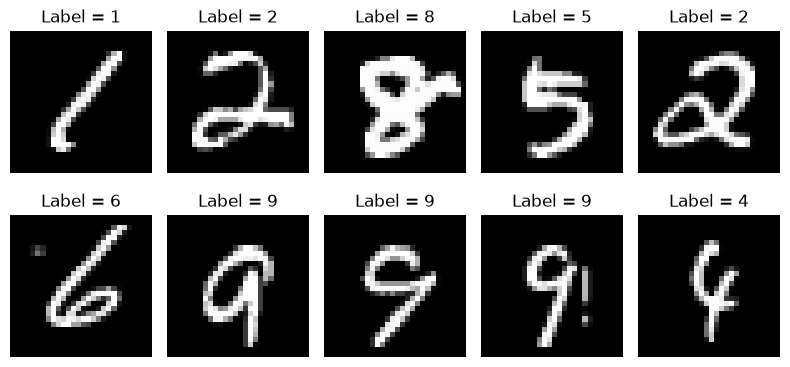

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

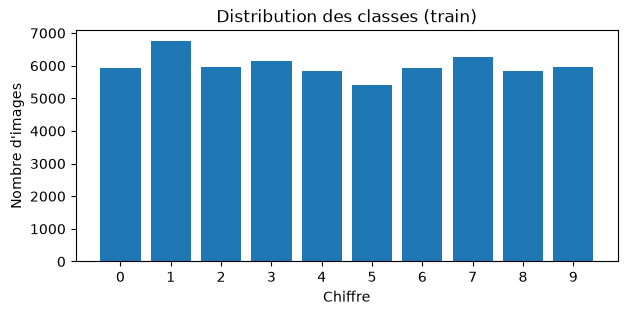

In [4]:
# Répartition des classes dans le jeu d'entraînement
counts = torch.bincount(train_dataset.targets, minlength=10)

plt.figure(figsize=(7, 3))
plt.bar(range(10), counts.numpy())
plt.xticks(range(10))
plt.xlabel("Chiffre")
plt.ylabel("Nombre d'images")
plt.title("Distribution des classes (train)")
plt.show()

# **2. Modèle discriminatif : apprendre $P(y|x)$**

Un classifieur reçoit une entrée $x$ et prédit une classe $y$ :

$$
x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat y
$$

Il apprend approximativement $P(y|x)$. Nous utilisons un réseau entièrement connecté (MLP).

In [5]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
print(classifier)
print("Nombre de paramètres :", sum(p.numel() for p in classifier.parameters()))

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Nombre de paramètres : 101770


### Fonction de perte

Pour une classification multi-classe :

$$
\mathcal{L}_{class} = \text{CrossEntropy}(\hat y, y)
$$

Le label $y$ est donc indispensable : c'est de l'apprentissage **supervisé**.

Epoch 1/5 - Loss = 0.4115


Epoch 2/5 - Loss = 0.1943


Epoch 3/5 - Loss = 0.1374


Epoch 4/5 - Loss = 0.1059


Epoch 5/5 - Loss = 0.0853


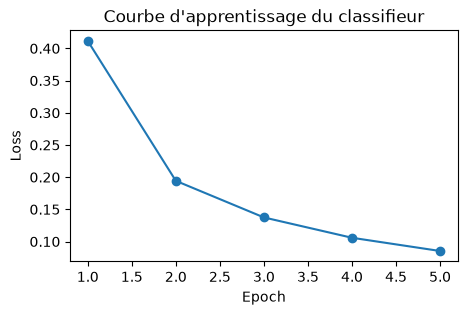

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

def train_classifier(model, loader, epochs=5):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        history.append(total_loss / len(loader))
        print(f"Epoch {epoch+1}/{epochs} - Loss = {history[-1]:.4f}")

    return history

clf_history = train_classifier(classifier, train_loader, epochs=5)

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(clf_history) + 1), clf_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Courbe d'apprentissage du classifieur")
plt.show()

### Évaluation

Première méthode : calcul manuel de l'accuracy.

In [7]:
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy (manuelle) = {100*accuracy:.2f}%")

Accuracy (manuelle) = 97.29%


Deuxième méthode : avec **torcheval** (accuracy globale, accuracy par classe et matrice de confusion).

C:\Users\Salah\Desktop\lab_pytorchV2 tp2\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


C:\Users\Salah\Desktop\lab_pytorchV2 tp2\.venv\Lib\site-packages\torcheval\metrics\functional\classification\accuracy.py:275: UserWarning: The reduce argument of torch.scatter with Tensor src is deprecated and will be removed in a future PyTorch release. Use torch.scatter_reduce instead for more reduction options. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorAdvancedIndexing.cpp:226.)
  num_correct = mask.new_zeros(num_classes).scatter_(0, target, mask, reduce="add")


Accuracy (torcheval) = 97.29%
  chiffre 0 : 98.88%
  chiffre 1 : 99.12%
  chiffre 2 : 97.67%
  chiffre 3 : 97.92%
  chiffre 4 : 97.76%
  chiffre 5 : 97.31%
  chiffre 6 : 97.81%
  chiffre 7 : 95.82%
  chiffre 8 : 95.89%
  chiffre 9 : 94.55%


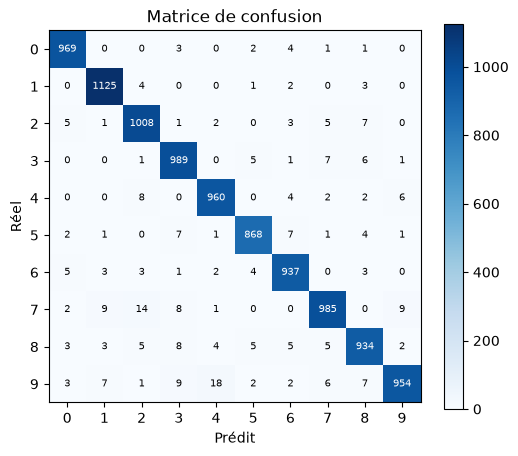

In [8]:
from torcheval.metrics import MulticlassAccuracy, MulticlassConfusionMatrix

@torch.no_grad()
def evaluate_with_torcheval(model, loader):
    model.eval()
    acc = MulticlassAccuracy(device=device)
    acc_per_class = MulticlassAccuracy(num_classes=10, average=None, device=device)
    cm = MulticlassConfusionMatrix(num_classes=10, device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        acc.update(logits, y)
        acc_per_class.update(logits, y)
        cm.update(logits, y)

    return acc.compute().item(), acc_per_class.compute().cpu(), cm.compute().cpu()

acc, acc_cls, conf = evaluate_with_torcheval(classifier, test_loader)
print(f"Accuracy (torcheval) = {100*acc:.2f}%")
for c in range(10):
    print(f"  chiffre {c} : {100*acc_cls[c]:.2f}%")

plt.figure(figsize=(6, 5))
plt.imshow(conf, cmap="Blues")
plt.colorbar()
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title("Matrice de confusion")
for i in range(10):
    for j in range(10):
        v = int(conf[i, j])
        plt.text(j, i, v, ha="center", va="center", fontsize=7,
                 color="white" if v > conf.max() / 2 else "black")
plt.show()

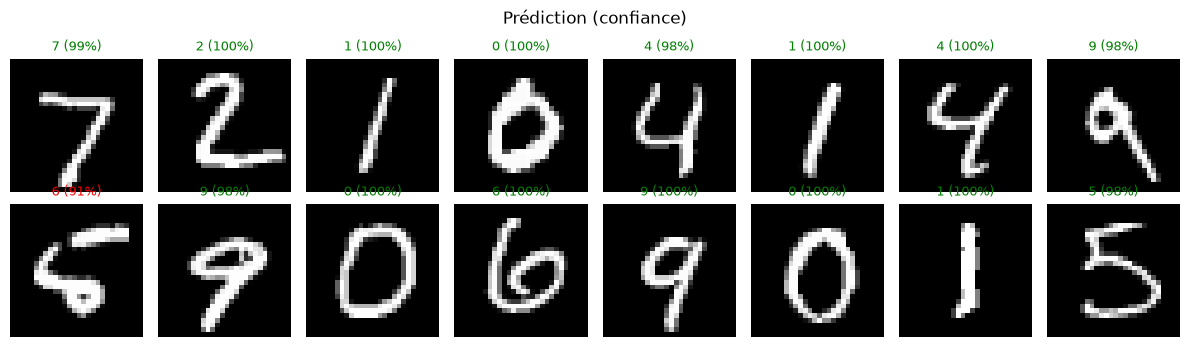

In [9]:
# Quelques prédictions sur le jeu de test (en rouge : erreurs)
classifier.eval()
x, y = next(iter(test_loader))
with torch.no_grad():
    probs = F.softmax(classifier(x.to(device)), dim=1).cpu()
pred = probs.argmax(dim=1)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x[i].squeeze(), cmap="gray")
    color = "green" if pred[i] == y[i] else "red"
    ax.set_title(f"{pred[i].item()} ({100*probs[i, pred[i]]:.0f}%)", color=color, fontsize=9)
    ax.axis("off")
plt.suptitle("Prédiction (confiance)")
plt.tight_layout()
plt.show()

**Conclusion** : le réseau apprend $x \rightarrow y$, il **discrimine** les classes (~97-98 % d'accuracy).
Mais il ne modélise pas $P(x)$ : il est incapable de **générer** une nouvelle image de chiffre.

# **3. Auto-encodeur simple**

Un auto-encodeur apprend à reconstruire son entrée :

$$
x \rightarrow \text{Encoder} \rightarrow z \rightarrow \text{Decoder} \rightarrow \hat x, \qquad \hat x \approx x
$$

Le vecteur $z$ est une **représentation latente** compressée. L'apprentissage devient $x \rightarrow x$ :
les labels ne sont plus nécessaires (apprentissage **non supervisé**).

Nous choisissons volontairement `latent_dim = 2` pour pouvoir visualiser l'espace latent.

In [10]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

ae = Autoencoder(latent_dim=2).to(device)
print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Loss de reconstruction

$$
\mathcal{L}_{rec}=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2 \quad (\texttt{MSELoss})
$$

In [11]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

def train_autoencoder(model, loader, epochs=10):
    model.train()
    history = []

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        history.append(total_loss / len(loader))
        print(f"Epoch {epoch+1}/{epochs} - Loss = {history[-1]:.4f}")

    return history

ae_history = train_autoencoder(ae, train_loader, epochs=10)

Epoch 1/10 - Loss = 0.0646


Epoch 2/10 - Loss = 0.0516


Epoch 3/10 - Loss = 0.0484


Epoch 4/10 - Loss = 0.0460


Epoch 5/10 - Loss = 0.0446


Epoch 6/10 - Loss = 0.0437


Epoch 7/10 - Loss = 0.0430


Epoch 8/10 - Loss = 0.0424


Epoch 9/10 - Loss = 0.0420


Epoch 10/10 - Loss = 0.0416


### Évaluation : erreur de reconstruction sur le jeu de test

In [12]:
@torch.no_grad()
def evaluate_autoencoder(model, loader):
    model.eval()
    total, n = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        total += F.mse_loss(model(x), x, reduction="sum").item()
        n += x.numel()
    return total / n

print(f"MSE test (AE, latent_dim=2) = {evaluate_autoencoder(ae, test_loader):.4f}")

MSE test (AE, latent_dim=2) = 0.0416


### Visualisation des reconstructions

Ligne 1 : images originales — Ligne 2 : images reconstruites.

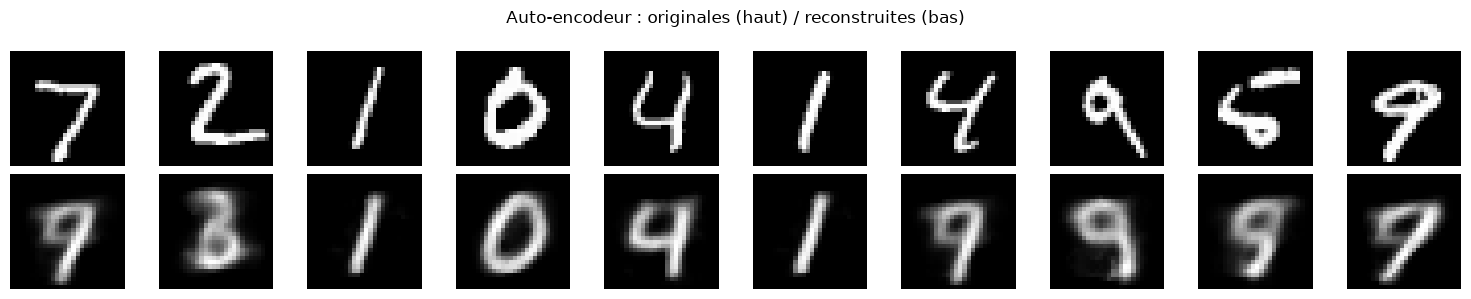

In [13]:
def show_reconstructions(model, title, vae=False):
    model.eval()
    x, _ = next(iter(test_loader))
    x = x[:10].to(device)

    with torch.no_grad():
        x_hat = model(x)[0] if vae else model(x)

    fig, axes = plt.subplots(2, 10, figsize=(15, 3))
    for i in range(10):
        axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
        axes[0, i].axis("off")
        axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
        axes[1, i].axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_reconstructions(ae, "Auto-encodeur : originales (haut) / reconstruites (bas)")

### Exploration de l'espace latent

Avec $z \in \mathbb{R}^2$, chaque image de test devient un point du plan, coloré par son label
(que l'AE n'a jamais vu pendant l'entraînement).

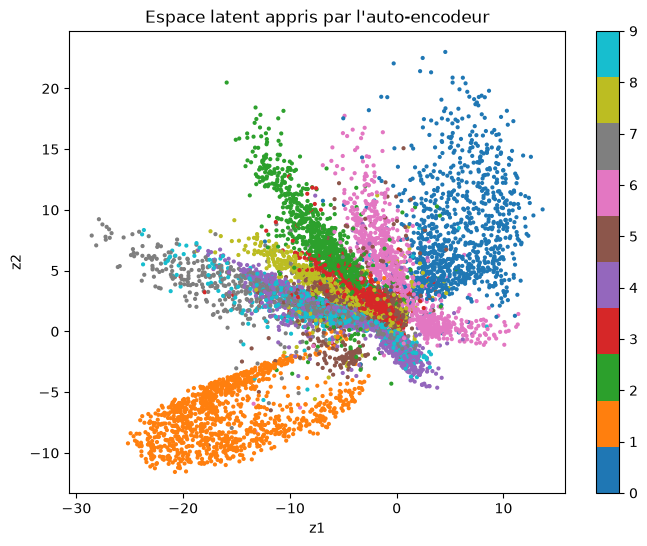

Étendue de z1 : -28.6 → 13.7
Étendue de z2 : -11.6 → 23.0


In [14]:
@torch.no_grad()
def latent_points(encode_fn, loader):
    zs, ys = [], []
    for x, y in loader:
        zs.append(encode_fn(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()

ae.eval()
Z_ae, Y = latent_points(ae.encode, test_loader)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z_ae[:, 0], Z_ae[:, 1], c=Y, s=4, cmap="tab10")
plt.xlabel("z1"); plt.ylabel("z2")
plt.title("Espace latent appris par l'auto-encodeur")
plt.colorbar(scatter, ticks=range(10))
plt.show()

print("Étendue de z1 :", Z_ae[:, 0].min().round(1), "→", Z_ae[:, 0].max().round(1))
print("Étendue de z2 :", Z_ae[:, 1].min().round(1), "→", Z_ae[:, 1].max().round(1))

### Génération à partir d'un chiffre connu

On calcule le vecteur latent moyen $\bar z$ de toutes les images d'un chiffre, puis on le décode.

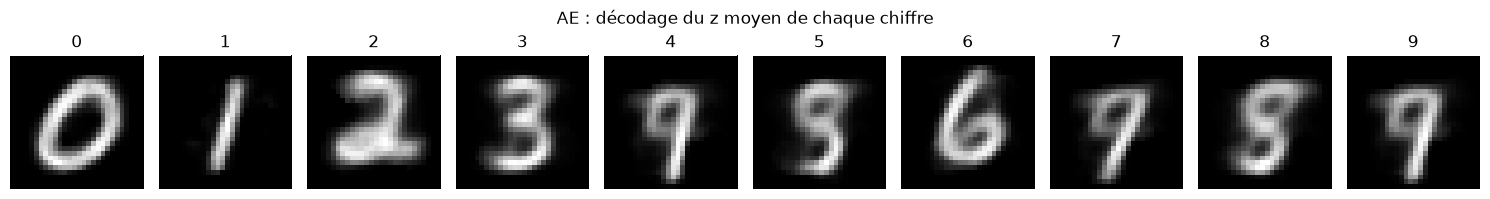

In [15]:
@torch.no_grad()
def generer_chiffre(encode_fn, decode_fn, dataloader, chiffre):
    somme_z, nombre = None, 0
    for images, labels in dataloader:
        images = images[labels == chiffre]
        if images.shape[0] == 0:
            continue
        z = encode_fn(images.to(device))
        s = z.sum(dim=0, keepdim=True)
        somme_z = s if somme_z is None else somme_z + s
        nombre += z.shape[0]
    return decode_fn(somme_z / nombre).cpu()

ae.eval()
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    img = generer_chiffre(ae.encode, ae.decode, train_loader, c)
    axes[c].imshow(img[0, 0], cmap="gray")
    axes[c].set_title(str(c))
    axes[c].axis("off")
plt.suptitle("AE : décodage du z moyen de chaque chiffre")
plt.tight_layout()
plt.show()

### Interpolation entre deux images

On passe linéairement de $z_A$ à $z_B$ : $z_t = (1-t)\,z_A + t\,z_B$.

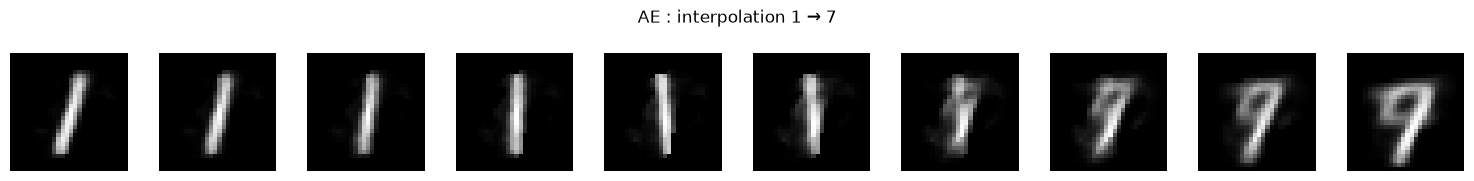

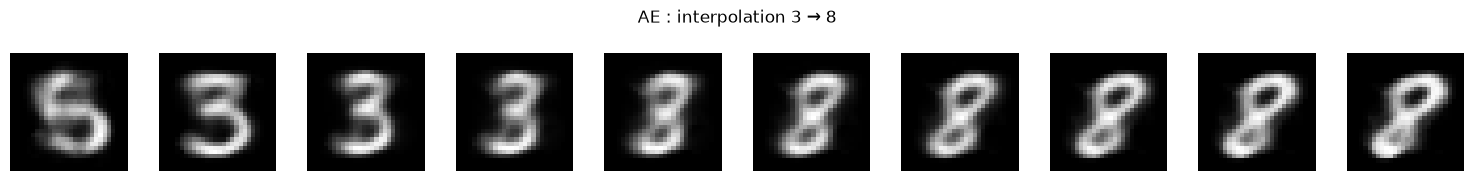

In [16]:
def find_index(dataset, digit):
    return (dataset.targets == digit).nonzero()[0].item()

@torch.no_grad()
def interpolate(encode_fn, decode_fn, digit_a, digit_b, steps=10):
    xa = test_dataset[find_index(test_dataset, digit_a)][0].unsqueeze(0).to(device)
    xb = test_dataset[find_index(test_dataset, digit_b)][0].unsqueeze(0).to(device)
    za, zb = encode_fn(xa), encode_fn(xb)
    ts = torch.linspace(0, 1, steps, device=device).unsqueeze(1)
    return decode_fn((1 - ts) * za + ts * zb).cpu()

def show_row(imgs, title):
    fig, axes = plt.subplots(1, len(imgs), figsize=(1.5 * len(imgs), 1.8))
    for ax, img in zip(axes, imgs):
        ax.imshow(img.squeeze(), cmap="gray")
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

ae.eval()
show_row(interpolate(ae.encode, ae.decode, 1, 7), "AE : interpolation 1 → 7")
show_row(interpolate(ae.encode, ae.decode, 3, 8), "AE : interpolation 3 → 8")

### Limite de l'auto-encodeur classique : échantillonner un $z$ au hasard

Rien ne garantit que l'espace latent de l'AE soit continu, régulier, centré, ni distribué selon une loi connue.
Si on tire $z \sim \mathcal{N}(0, I)$ (ou dans un grand carré), le décodeur produit souvent des images peu réalistes.

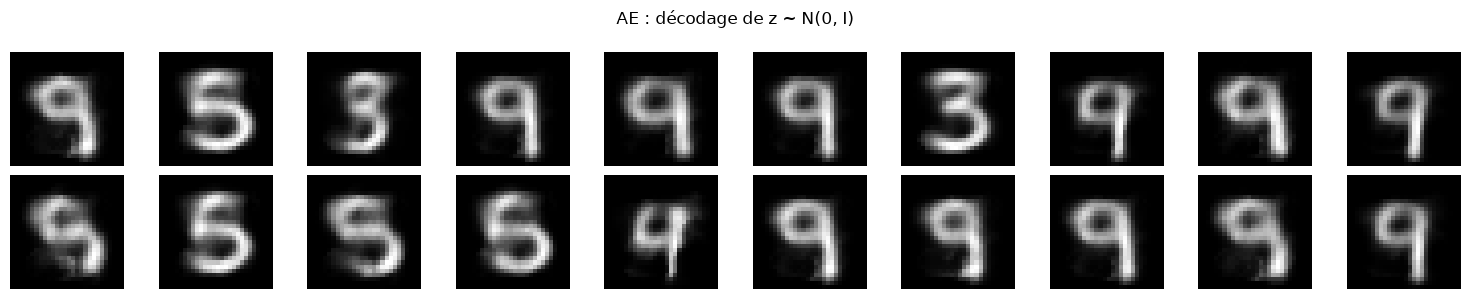

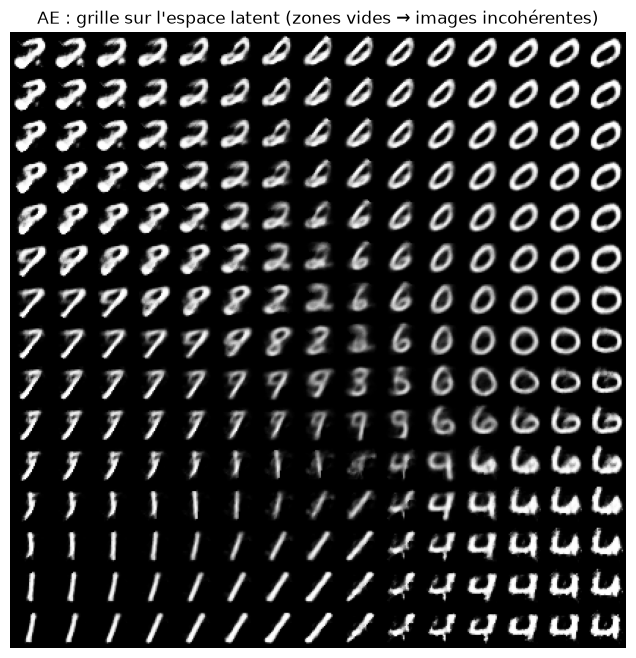

In [17]:
ae.eval()
with torch.no_grad():
    z_rand = torch.randn(20, 2, device=device)
    samples_ae = ae.decode(z_rand).cpu()

    # Grille couvrant toute l'étendue de l'espace latent de l'AE
    n = 15
    gx = np.linspace(Z_ae[:, 0].min(), Z_ae[:, 0].max(), n)
    gy = np.linspace(Z_ae[:, 1].max(), Z_ae[:, 1].min(), n)
    zz = torch.tensor([[xi, yi] for yi in gy for xi in gx], dtype=torch.float32, device=device)
    grid_ae = ae.decode(zz).cpu().numpy()[:, 0]

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples_ae[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("AE : décodage de z ~ N(0, I)")
plt.tight_layout()
plt.show()

figure = grid_ae.reshape(n, n, 28, 28).transpose(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(8, 8))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("AE : grille sur l'espace latent (zones vides → images incohérentes)")
plt.show()

**Conclusion AE** : bonnes reconstructions et un espace latent qui regroupe les chiffres sans supervision,
mais cet espace est irrégulier (zones vides, échelle arbitraire). On ne sait pas où échantillonner :
l'AE n'est pas un vrai modèle génératif. Cette limite motive le **Variational Auto-Encoder**.

# **4. Variational Auto-Encoder (VAE)**

### Principe

Au lieu d'associer $x$ à un point latent unique, le VAE associe $x$ à une **distribution** :

$$
q(z|x)=\mathcal{N}\big(\mu(x),\,\sigma^2(x)\big)
$$

L'encodeur produit $\mu(x)$ et $\log \sigma^2(x)$.

### Reparameterization trick

Pour échantillonner $z \sim \mathcal{N}(\mu,\sigma^2)$ tout en gardant la rétropropagation :

$$
\epsilon \sim \mathcal{N}(0,I), \qquad \boxed{z=\mu+\sigma\odot\epsilon}
$$

In [18]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE(latent_dim=2).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Loss du VAE

Deux termes :
- **Reconstruction** $\mathcal{L}_{rec}$ (entropie croisée binaire pixel par pixel) ;
- **Régularisation** de l'espace latent : $D_{KL}\left(q(z|x) \parallel \mathcal N(0,I)\right)$.

Pour une gaussienne diagonale :

$$
D_{KL} = -\frac12 \sum \left(1+\log\sigma^2-\mu^2-\sigma^2\right)
$$

$$
\boxed{\mathcal L_{VAE} = \mathcal L_{rec} + \beta\, D_{KL}}
$$

In [19]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec_loss + beta * kl_loss, rec_loss, kl_loss

vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()
    history = {"loss": [], "rec": [], "kl": []}

    for epoch in range(epochs):
        total_loss = total_rec = total_kl = 0

        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, rec, kl = vae_loss(x_hat, x, mu, logvar, beta=beta)

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)
        history["loss"].append(total_loss / n)
        history["rec"].append(total_rec / n)
        history["kl"].append(total_kl / n)
        print(f"Epoch {epoch+1}/{epochs} | Loss={total_loss/n:.2f} | Rec={total_rec/n:.2f} | KL={total_kl/n:.2f}")

    return history

vae_history = train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=195.53 | Rec=191.78 | KL=3.75


Epoch 2/20 | Loss=167.40 | Rec=162.48 | KL=4.93


Epoch 3/20 | Loss=161.52 | Rec=156.21 | KL=5.31


Epoch 4/20 | Loss=157.48 | Rec=151.91 | KL=5.57


Epoch 5/20 | Loss=154.60 | Rec=148.87 | KL=5.74


Epoch 6/20 | Loss=152.55 | Rec=146.70 | KL=5.85


... (10 outputs left out)

Epoch 17/20 | Loss=143.43 | Rec=137.06 | KL=6.37


Epoch 18/20 | Loss=143.05 | Rec=136.64 | KL=6.41


Epoch 19/20 | Loss=142.58 | Rec=136.15 | KL=6.43


Epoch 20/20 | Loss=142.28 | Rec=135.83 | KL=6.46


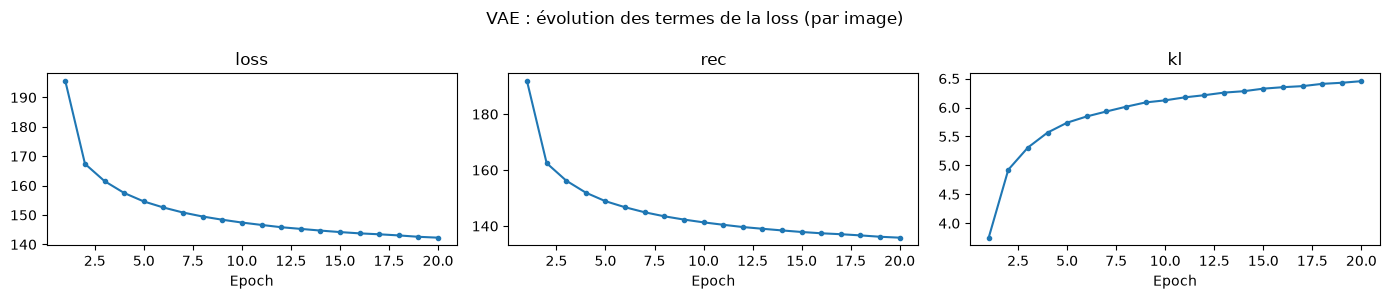

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, key in zip(axes, ["loss", "rec", "kl"]):
    ax.plot(range(1, len(vae_history[key]) + 1), vae_history[key], marker="o", ms=3)
    ax.set_title(key)
    ax.set_xlabel("Epoch")
plt.suptitle("VAE : évolution des termes de la loss (par image)")
plt.tight_layout()
plt.show()

### Évaluation sur le jeu de test

In [21]:
@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    tot = rec_t = kl_t = mse_t = 0.0
    for x, _ in loader:
        x = x.to(device)
        mu, logvar = model.encode(x)
        x_hat = model.decode(mu)          # reconstruction déterministe (z = mu)
        loss, rec, kl = vae_loss(x_hat, x, mu, logvar)
        tot += loss.item(); rec_t += rec.item(); kl_t += kl.item()
        mse_t += F.mse_loss(x_hat, x, reduction="sum").item()
    n = len(loader.dataset)
    return tot / n, rec_t / n, kl_t / n, mse_t / (n * 784)

loss_t, rec_t, kl_t, mse_vae = evaluate_vae(vae, test_loader)
mse_ae = evaluate_autoencoder(ae, test_loader)
print(f"VAE test : Loss={loss_t:.2f} | Rec={rec_t:.2f} | KL={kl_t:.2f}")
print(f"MSE test : AE = {mse_ae:.4f} | VAE = {mse_vae:.4f}")

VAE test : Loss=142.68 | Rec=136.15 | KL=6.53
MSE test : AE = 0.0416 | VAE = 0.0375


### Reconstruction avec le VAE

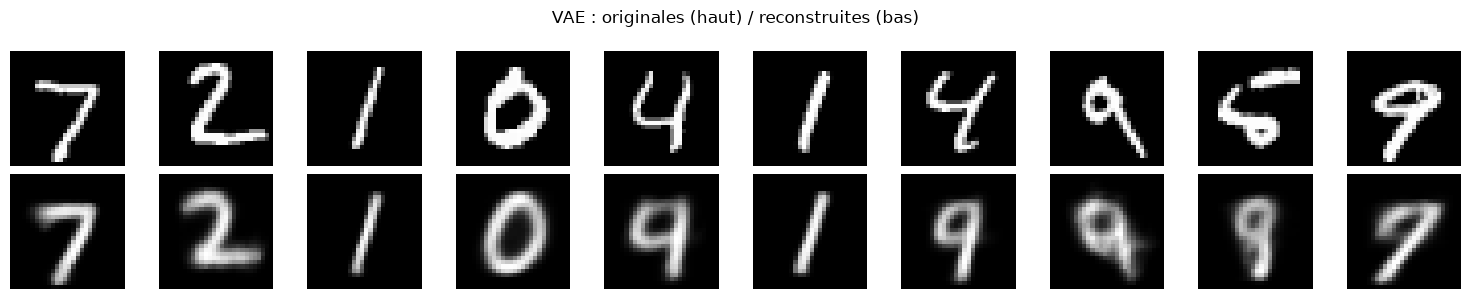

In [22]:
show_reconstructions(vae, "VAE : originales (haut) / reconstruites (bas)", vae=True)

### Espace latent du VAE

On utilise le vecteur moyen $\mu$ comme représentation latente. Grâce au terme KL, les points
sont centrés autour de 0 et l'espace est compact et continu, proche de $\mathcal N(0, I)$.

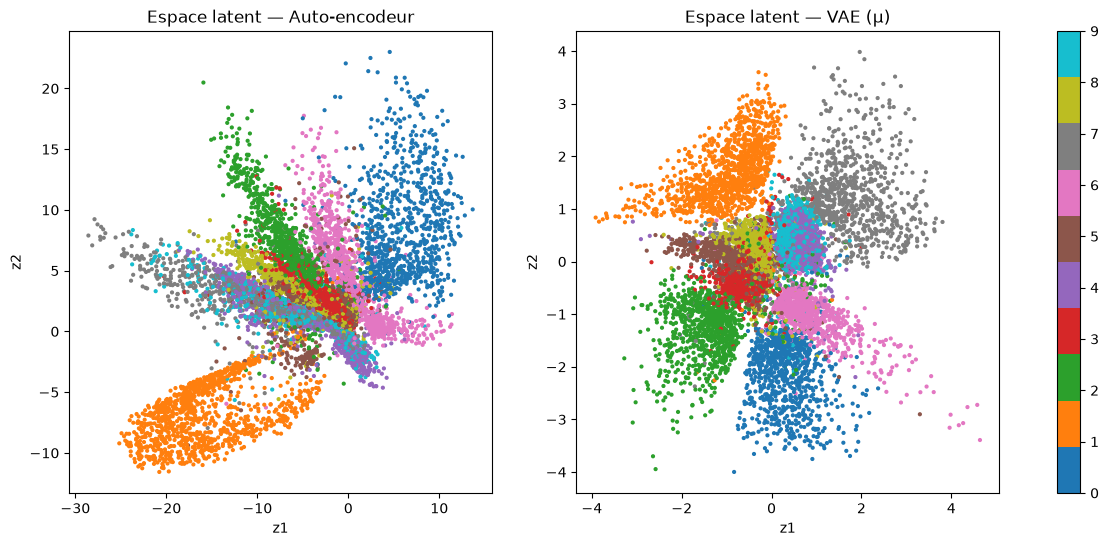

VAE : moyenne de μ = [-0.04 -0.07] | écart-type = [1.05 1.19]


In [23]:
vae.eval()
MU, Y = latent_points(lambda x: vae.encode(x)[0], test_loader)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, Z, title in [(axes[0], Z_ae, "Auto-encodeur"), (axes[1], MU, "VAE (μ)")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=Y, s=4, cmap="tab10")
    ax.set_title(f"Espace latent — {title}")
    ax.set_xlabel("z1"); ax.set_ylabel("z2")
fig.colorbar(sc, ax=axes, ticks=range(10))
plt.show()

print("VAE : moyenne de μ =", MU.mean(axis=0).round(2), "| écart-type =", MU.std(axis=0).round(2))

### Générer de nouvelles images

C'est le point essentiel : plus besoin d'image d'entrée. On échantillonne directement

$$
z \sim \mathcal N(0,I), \qquad x_{new}=\text{Decoder}(z)
$$

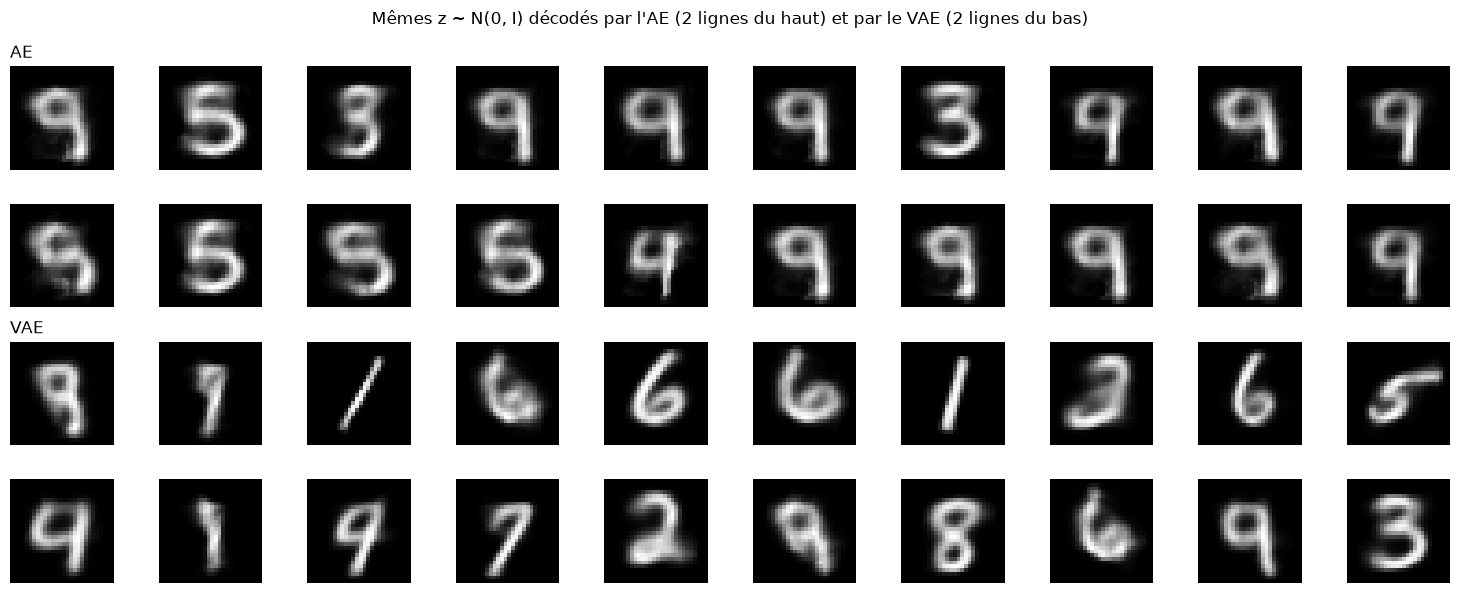

In [24]:
vae.eval()
with torch.no_grad():
    samples = vae.decode(z_rand).cpu()   # mêmes z aléatoires que pour l'AE

fig, axes = plt.subplots(4, 10, figsize=(15, 6))
for i in range(20):
    axes[i // 10, i % 10].imshow(samples_ae[i].squeeze(), cmap="gray")
    axes[2 + i // 10, i % 10].imshow(samples[i].squeeze(), cmap="gray")
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_title("AE", loc="left")
axes[2, 0].set_title("VAE", loc="left")
plt.suptitle("Mêmes z ~ N(0, I) décodés par l'AE (2 lignes du haut) et par le VAE (2 lignes du bas)")
plt.tight_layout()
plt.show()

### Exploration manuelle de l'espace latent

Avec un espace latent 2D, on construit une grille de points dans $[-3, 3]^2$ et on observe les images produites par le décodeur.

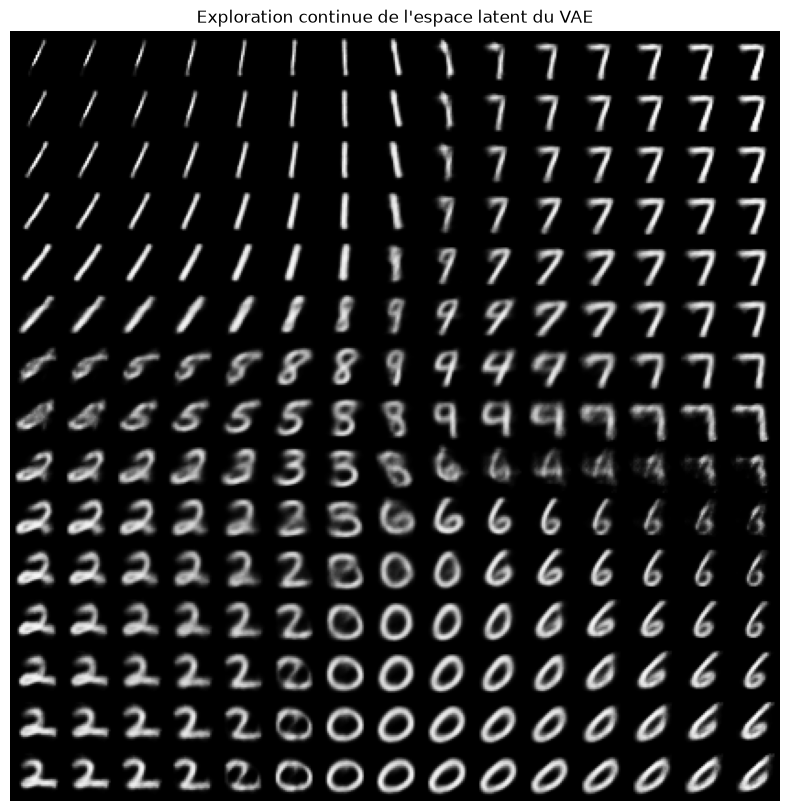

In [25]:
vae.eval()
n = 15
grid_x = np.linspace(-3, 3, n)
grid_y = np.linspace(3, -3, n)
figure = np.zeros((28 * n, 28 * n))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            figure[i*28:(i+1)*28, j*28:(j+1)*28] = vae.decode(z).cpu().numpy()[0, 0]

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

### Interpolation et génération par chiffre avec le VAE

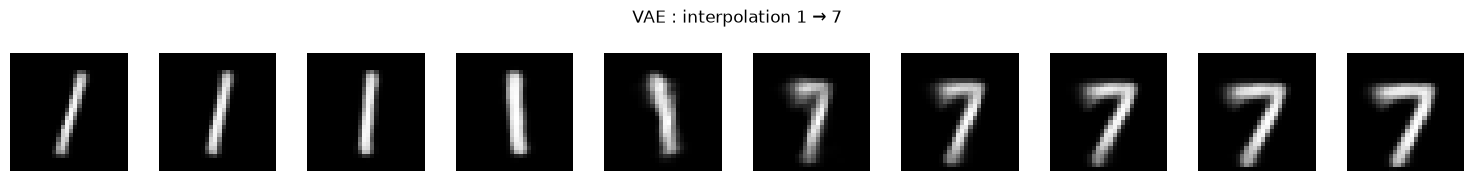

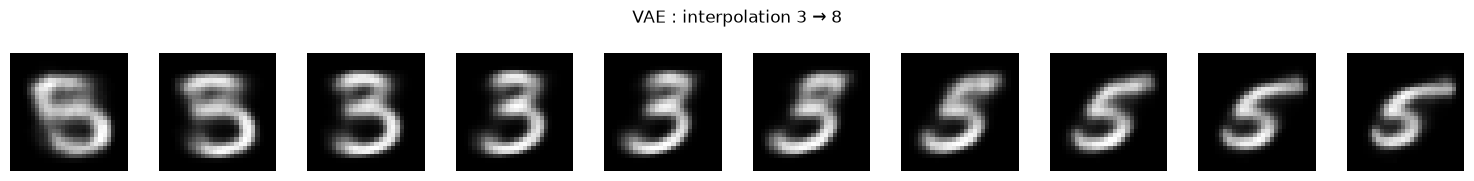

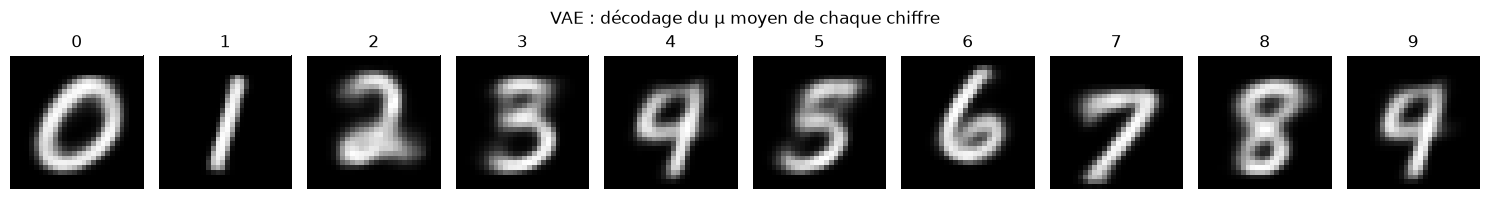

In [26]:
vae.eval()
encode_mu = lambda x: vae.encode(x)[0]
show_row(interpolate(encode_mu, vae.decode, 1, 7), "VAE : interpolation 1 → 7")
show_row(interpolate(encode_mu, vae.decode, 3, 8), "VAE : interpolation 3 → 8")

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    img = generer_chiffre(encode_mu, vae.decode, train_loader, c)
    axes[c].imshow(img[0, 0], cmap="gray")
    axes[c].set_title(str(c))
    axes[c].axis("off")
plt.suptitle("VAE : décodage du μ moyen de chaque chiffre")
plt.tight_layout()
plt.show()

# **Synthèse**

| Modèle | Ce qu'il apprend | Labels | Peut générer ? |
|---|---|---|---|
| Classifieur (discriminatif) | $P(y\mid x)$ | Oui | Non |
| Auto-encodeur | $x \rightarrow z \rightarrow \hat x$ (compression) | Non | Mal : espace latent irrégulier, on ne sait pas où échantillonner |
| VAE | $q(z\mid x)$ proche de $\mathcal N(0,I)$ + décodeur $p(x\mid z)$ | Non | Oui : $z \sim \mathcal N(0,I)$ donne des chiffres plausibles, l'espace est continu |

- Le **classifieur** atteint une très bonne accuracy mais ne sait pas produire d'image.
- L'**AE** reconstruit bien et organise les chiffres en clusters sans supervision, mais son espace latent a des trous.
- Le **VAE** produit des images un peu plus floues, mais ici sa MSE de reconstruction reste comparable (et même légèrement
  meilleure : 0.0375 contre 0.0416 pour l'AE, grâce à un encodeur plus large et 20 epochs). Surtout, son espace latent est
  régulier, centré (μ ≈ 0, écart-type ≈ 1) et continu : on peut échantillonner, interpoler et explorer pour **générer** de nouveaux chiffres.